# Slot-count intervention in the identity format — all four conditions, eight runs, one Run all

**Question.** Five-slot identity training on k ∈ {0,2,3,4,5} generalized to singletons (notebook 10); five-slot
training on {0,2}, {0,2,3}, {0,2,3,4} did not (notebooks 12–14). Every training instruction in those three failing
supports contains at least one `<identity>` (I); train02345 also contains k=5 instructions with no I. This notebook
changes the number of physical slots S while keeping each logical training support fixed:

| condition | S | train k | no-I training records | held-out tests |
|---|---|---|---|---|
| slots2_train02 | 2 | 0, 2 | 640,000 (k=2) | k=1 at both positions |
| slots3_train023 | 3 | 0, 2, 3 | 426,666 (k=3) | k=1 at all 3 positions |
| slots4_train0234 | 4 | 0, 2, 3, 4 | 320,000 (k=4) | k=1 at all 4 positions |
| slots6_train02345 | 6 | 0, 2, 3, 4, 5 | 0 | k=1 at all 6 positions; all 729 six-operation words |

**Format.**
* Every instruction has exactly S VISIBLE tokens: the k A/B/C tokens fill a uniformly random ordered k-subset of the
  slots, and the rest are the learnable `<identity>` token. There is no PAD and no hidden slot.
* Each sequence has 77+S tokens with contiguous learned positions, and the shared position table has 83 rows.

**Recipe.** Notebooks 10/12–14 unchanged:
* Transformer AR and Looped AR, AdamW 3e-4, 5000 updates × 256, seed 42.
* Per-k allocation as in notebooks 12–14.
* For supports 02/023/0234, the logical (word, grid, target) stream and batch order are identical to the S=5 runs;
  only the layout changes. 02345 is a new stream, since notebook 10 used a different sampler.
* Common fresh initialization: the historical S=5 init with one added position row.
* Selection uses validation answer-digit CE (EOS excluded), macro-averaged over the trained k.

**Not a pure identity-token ablation.**
* Changing S also changes sequence length, downstream absolute positions, layouts, filler counts and compute.
* S=2/train02 keeps the even-count H ambiguity.
* Six-operation failure at S=6 confounds a larger k with the first-ever zero-I inputs.

One seed: descriptive only.

**Workflow.**
1. Run all: setup → shared audits → the sequential queue of eight runs (train → evaluate → diagnose → export each) →
   consolidated comparison.
2. If interrupted, Run all again: verified stages are skipped, training resumes from `state.pt`, and missing
   evaluation chunks are recomputed.
3. After any partial progress, the comparison cells can be rerun alone; they never train or build models.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 12d7cacfb8ac5891535aa7b9b44748006f2405cd


In [2]:
# --- CONFIGURATION (the only cell to edit) --------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")   # "full" | "smoke" (tiny CPU integration check, separate paths, NOT results)
SEED = int(os.environ.get("DECOMP_SEED", 42))   # no automatic seed sweep
RUN_CONDITIONS = ["slots2_train02", "slots3_train023", "slots4_train0234", "slots6_train02345"]   # default: all four
RUN_MODELS = ["transformer_ar", "looped_transformer_ar"]                                          # default: both
RUN_STAGES = ["train", "evaluate", "diagnose", "export"]                                          # default: every stage
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE
    else "/content/decompositionality_results" if IN_COLAB else str(REPO_DIR / "results"))
SLOT_ROOT = f"{RESULTS_ROOT}/identity_ar_slot_count"
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"
MICROBATCH = None          # None = probe the largest safe microbatch (effective batch stays 256)
EVAL_CHUNK_GRIDS = 100     # 10 resumable chunks per run
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import json, pathlib
import pandas as pd
from IPython.display import Image, display
from decompositionality.config import make_experiment_config
from decompositionality import idslot as I, idslot_reports as R
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 120)
FAMILY_ROOT = pathlib.Path(SLOT_ROOT) if MODE == "full" else pathlib.Path(SLOT_ROOT) / "smoke"
_c = make_experiment_config(RUN_CONDITIONS[0], MODE, SLOT_ROOT, RUN_MODELS, seed=SEED)
expected = dict(lr=3e-4, weight_decay=0.01, warmup_steps=250, min_lr=3e-5, grad_clip=1.0, val_every=250,
                optimizer_steps=5000, effective_batch_size=256)
print("resolved recipe:", _c.train.semantic_dict())
print("discrepancies from expected defaults:",
      {k: (getattr(_c.train, k), v) for k, v in expected.items() if getattr(_c.train, k) != v} or "none")
if MODE == "smoke":
    print("*** SMOKE MODE: tiny integration run under", FAMILY_ROOT, "- NOT benchmark results ***")
QUEUE = [(e, m) for e in R.CONDITIONS if e in RUN_CONDITIONS for m in R.MODELS if m in RUN_MODELS]
print(f"queue ({len(QUEUE)} runs, sequential):", " -> ".join(f"{e}/{m}" for e, m in QUEUE), "| stages:", RUN_STAGES)
print("results ->", FAMILY_ROOT)


Mounted at /content/drive
resolved recipe: {'seed': 42, 'optimizer_steps': 5000, 'effective_batch_size': 256, 'lr': 0.0003, 'min_lr': 3e-05, 'weight_decay': 0.01, 'betas': [0.9, 0.95], 'warmup_steps': 250, 'grad_clip': 1.0, 'val_every': 250}
discrepancies from expected defaults: none
queue (8 runs, sequential): slots2_train02/transformer_ar -> slots2_train02/looped_transformer_ar -> slots3_train023/transformer_ar -> slots3_train023/looped_transformer_ar -> slots4_train0234/transformer_ar -> slots4_train0234/looped_transformer_ar -> slots6_train02345/transformer_ar -> slots6_train02345/looped_transformer_ar | stages: ['train', 'evaluate', 'diagnose', 'export']
results -> /content/drive/MyDrive/decompositionality_results/identity_ar_slot_count


In [3]:
from decompositionality.utils import environment_info
print(json.dumps(environment_info(REPO_DIR), indent=1))


{
 "python": "3.13.16",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "torch": "2.14.1+cu130",
 "numpy": "2.4.6",
 "cuda_available": true,
 "repo_commit": "12d7cacfb8ac5891535aa7b9b44748006f2405cd",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "gpu": "NVIDIA RTX PRO 6000 Blackwell Server Edition",
 "cuda": "13.0",
 "bf16_supported": true,
 "gpu_total_memory_gb": 94.97
}


In [4]:
# --- Shared audits (stop on failure): supports/counts, stream matching, layouts/masks/decoding, init, manifests -
AUD = FAMILY_ROOT / "audits" / f"seed_{SEED}"; AUD.mkdir(parents=True, exist_ok=True)
from decompositionality.data import load_or_build_manifests
man = load_or_build_manifests(FAMILY_ROOT / "manifests", SEED)
sup = R.support_audit(_c.train.effective_batch_size, _c.train.optimizer_steps)
stream, unif = R.stream_audit(SEED, _c.train.effective_batch_size, heldout=man.heldout_bytes)
lay = R.layout_audit(SEED)
ini = R.init_audit(SEED)
mb = R.microbatch_audit()
assert stream.deterministic_replay.all() and stream.only_training_k.all() and mb["equal_within_1e-6"]
assert (stream[stream.historical_S5_stream.str.startswith("idext")].same_words_grids_targets_order_as_S5 == True).all()
assert ini.identical_init_across_4_conditions.all() and ini.shared_tensors_equal_historical_S5_construction.all()
cfgs = {e: make_experiment_config(e, MODE, SLOT_ROOT, RUN_MODELS, seed=SEED) for e in R.CONDITIONS}
ctxs = {e: R.prepare_condition(c, str(REPO_DIR), {
            "five-slot count extrapolation (nb 12-14)": f"{RESULTS_ROOT}/identity_ar_count_extrapolation/manifests/manifest.json",
            "identity_02345 (nb 10)": f"{RESULTS_ROOT}/identity_varlen_02345_all_models/manifests/manifest.json"})
        for e, c in cfgs.items()}
tm = R.test_manifest_audit(ctxs)
for name, df in (("support", sup), ("stream_match", stream), ("placement_uniformity", unif), ("layout", lay),
                 ("initialization", ini), ("test_manifest", tm)):
    df.to_csv(AUD / f"{name}.csv", index=False); print(f"\n[{name}]"); display(df)
(AUD / "microbatch.json").write_text(json.dumps(mb, indent=1)); print("[microbatch]", mb)
print("training-transformation coverage:"); display(I.transformation_coverage())
del ctxs


/content/Decompositionality/src/decompositionality/idslot_reports.py:335: UserWarning: Seems like `optimizer.step()` has been overridden after learning rate scheduler initialization. Please, make sure to call `optimizer.step()` before `lr_scheduler.step()`. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step = lambda *a, **k: (calls.__setitem__("sched", calls["sched"] + 1), s_step(*a, **k))[1]


[slots2_train02] S=2 | manifests hash bdf24c327a65 ({'five-slot count extrapolation (nb 12-14)': 'identical', 'identity_02345 (nb 10)': 'identical'}) | validation 600 | test 16,000
[slots3_train023] S=3 | manifests hash bdf24c327a65 ({'five-slot count extrapolation (nb 12-14)': 'identical', 'identity_02345 (nb 10)': 'identical'}) | validation 900 | test 46,000
[slots4_train0234] S=4 | manifests hash bdf24c327a65 ({'five-slot count extrapolation (nb 12-14)': 'identical', 'identity_02345 (nb 10)': 'identical'}) | validation 1200 | test 130,000
[slots6_train02345] S=6 | manifests hash bdf24c327a65 ({'five-slot count extrapolation (nb 12-14)': 'identical', 'identity_02345 (nb 10)': 'identical'}) | validation 1500 | test 1,108,000

[support]


,condition,S,k,identity_tokens,status,records_update_0,records_update_1,records_full_run,logical_words,physical_patterns
0,slots2_train02,2,0,2,train,128,128,640000,1,1
1,slots2_train02,2,1,1,HELD OUT,0,0,0,3,6
2,slots2_train02,2,2,0,train,128,128,640000,9,9
3,slots3_train023,3,0,3,train,86,85,426667,1,1
4,slots3_train023,3,1,2,HELD OUT,0,0,0,3,9
5,slots3_train023,3,2,1,train,85,86,426667,9,27
6,slots3_train023,3,3,0,train,85,85,426666,27,27
7,slots4_train0234,4,0,4,train,64,64,320000,1,1
8,slots4_train0234,4,1,3,HELD OUT,0,0,0,3,12
9,slots4_train0234,4,2,2,train,64,64,320000,9,54



[stream_match]


,condition,update,records,deterministic_replay,only_training_k,identity_tokens_equal_S_minus_k,no_identity_records,historical_S5_stream,same_words_grids_targets_order_as_S5
0,slots2_train02,0,256,True,True,True,128,idext_train02,True
1,slots2_train02,1,256,True,True,True,128,idext_train02,True
2,slots2_train02,2,256,True,True,True,128,idext_train02,True
3,slots2_train02,3,256,True,True,True,128,idext_train02,True
4,slots2_train02,2499,256,True,True,True,128,idext_train02,True
5,slots2_train02,4999,256,True,True,True,128,idext_train02,True
6,slots3_train023,0,256,True,True,True,85,idext_train023,True
7,slots3_train023,1,256,True,True,True,85,idext_train023,True
8,slots3_train023,2,256,True,True,True,86,idext_train023,True
9,slots3_train023,3,256,True,True,True,85,idext_train023,True



[placement_uniformity]


... (5 outputs left out)


[test_manifest]


,condition,S,grids,seen_records,singleton_records,six_op_records,total,expected_total,singleton_cells_covered,singleton_cells_expected,six_op_words,oracle_target_mismatches,seen_words,seen_words_expected,pad_tokens,identity_count_mismatches
0,slots2_train02,2,1000,10000,6000,0,16000,16000,6,6,0,0,10,10,0,0
1,slots3_train023,3,1000,37000,9000,0,46000,46000,9,9,0,0,37,37,0,0
2,slots4_train0234,4,1000,118000,12000,0,130000,130000,12,12,0,0,118,118,0,0
3,slots6_train02345,6,1000,361000,18000,729000,1108000,1108000,18,18,729,0,361,361,0,0


[microbatch] {'max_abs_param_update_difference_mb16_vs_mb4': 1.3969838619232178e-08, 'equal_within_1e-6': True, 'optimizer_steps_per_update': [1, 1], 'scheduler_steps_per_update': [1, 1]}
training-transformation coverage:


,condition,S,k,status,words,words_with_training_transform,words_with_NEW_transform,n_training_transforms
0,slots2_train02,2,0,train,1,1,0,9
1,slots2_train02,2,1,HELD OUT,3,0,3,9
2,slots2_train02,2,2,train,9,9,0,9
3,slots3_train023,3,0,train,1,1,0,30
4,slots3_train023,3,1,HELD OUT,3,3,0,30
5,slots3_train023,3,2,train,9,9,0,30
6,slots3_train023,3,3,train,27,27,0,30
7,slots4_train0234,4,0,train,1,1,0,62
8,slots4_train0234,4,1,HELD OUT,3,3,0,62
9,slots4_train0234,4,2,train,9,9,0,62


In [5]:
# --- Sequential eight-run driver (one model/optimizer on the GPU at a time; resumable; skips verified stages) ---
status = R.run_queue(SLOT_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, RUN_STAGES, repo_dir=str(REPO_DIR),
                     compare_manifests={"five-slot count extrapolation (nb 12-14)":
                                        f"{RESULTS_ROOT}/identity_ar_count_extrapolation/manifests/manifest.json"},
                     chunk_grids=EVAL_CHUNK_GRIDS, device=DEVICE, dtype=DTYPE, microbatch=MICROBATCH)
display(status)


Resolved queue (sequential): slots2_train02/transformer_ar -> slots2_train02/looped_transformer_ar -> slots3_train023/transformer_ar -> slots3_train023/looped_transformer_ar -> slots4_train0234/transformer_ar -> slots4_train0234/looped_transformer_ar -> slots6_train02345/transformer_ar -> slots6_train02345/looped_transformer_ar | stages ['train', 'evaluate', 'diagnose', 'export']
[slots2_train02] S=2 | manifests hash bdf24c327a65 ({'five-slot count extrapolation (nb 12-14)': 'identical'}) | validation 600 | test 16,000

=== slots2_train02 (S=2) / transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,703,252 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 0.7383 (best) | subset(64) exact 0.516 cell 0.701
  [val @ 500] cell CE 0.0074 (best) | subset(64) exact 0.938 cell 0.998
  step 675/5000 loss 0.0024 lr 2.95e-04 | 33.37 steps/s, 8543 ex/s | ETA 2.2 min
  [val @ 750] cell CE 0.0042 (be

,condition,S,model,train,evaluate,diagnose,export,complete,selected_step,records
0,slots2_train02,2,transformer_ar,done,done,done,done,True,5000,16000
1,slots2_train02,2,looped_transformer_ar,done,done,done,done,True,5000,16000
2,slots3_train023,3,transformer_ar,done,done,done,done,True,4500,46000
3,slots3_train023,3,looped_transformer_ar,done,done,done,done,True,5000,46000
4,slots4_train0234,4,transformer_ar,done,done,done,done,True,5000,130000
5,slots4_train0234,4,looped_transformer_ar,done,done,done,done,True,4750,130000
6,slots6_train02345,6,transformer_ar,done,done,done,done,True,4500,1108000
7,slots6_train02345,6,looped_transformer_ar,done,done,done,done,True,4750,1108000


Run status: slots2_train02/transformer_ar: analysed; slots2_train02/looped_transformer_ar: analysed; slots3_train023/transformer_ar: analysed; slots3_train023/looped_transformer_ar: analysed; slots4_train0234/transformer_ar: analysed; slots4_train0234/looped_transformer_ar: analysed; slots6_train02345/transformer_ar: analysed; slots6_train02345/looped_transformer_ar: analysed


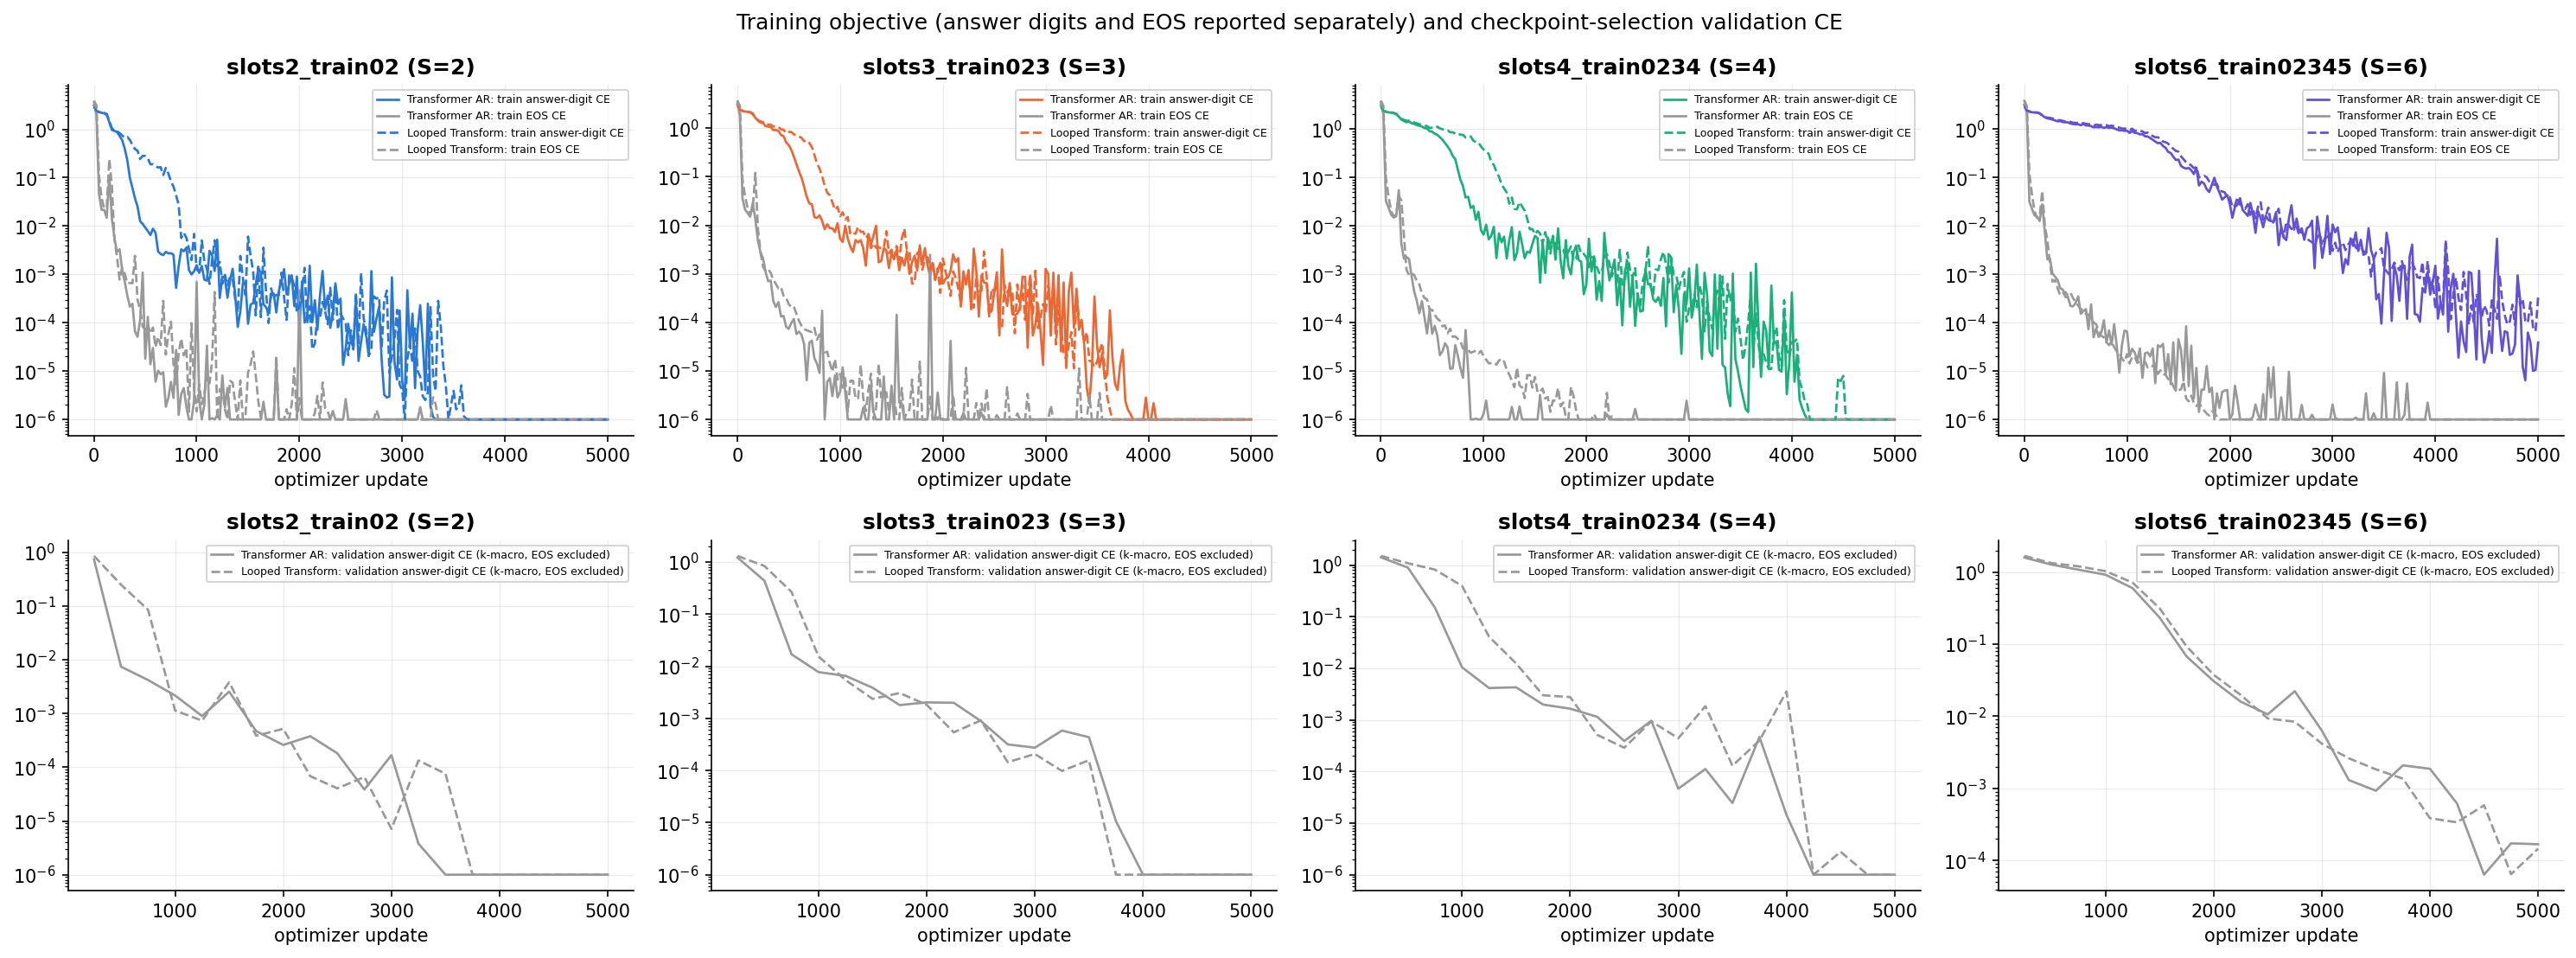

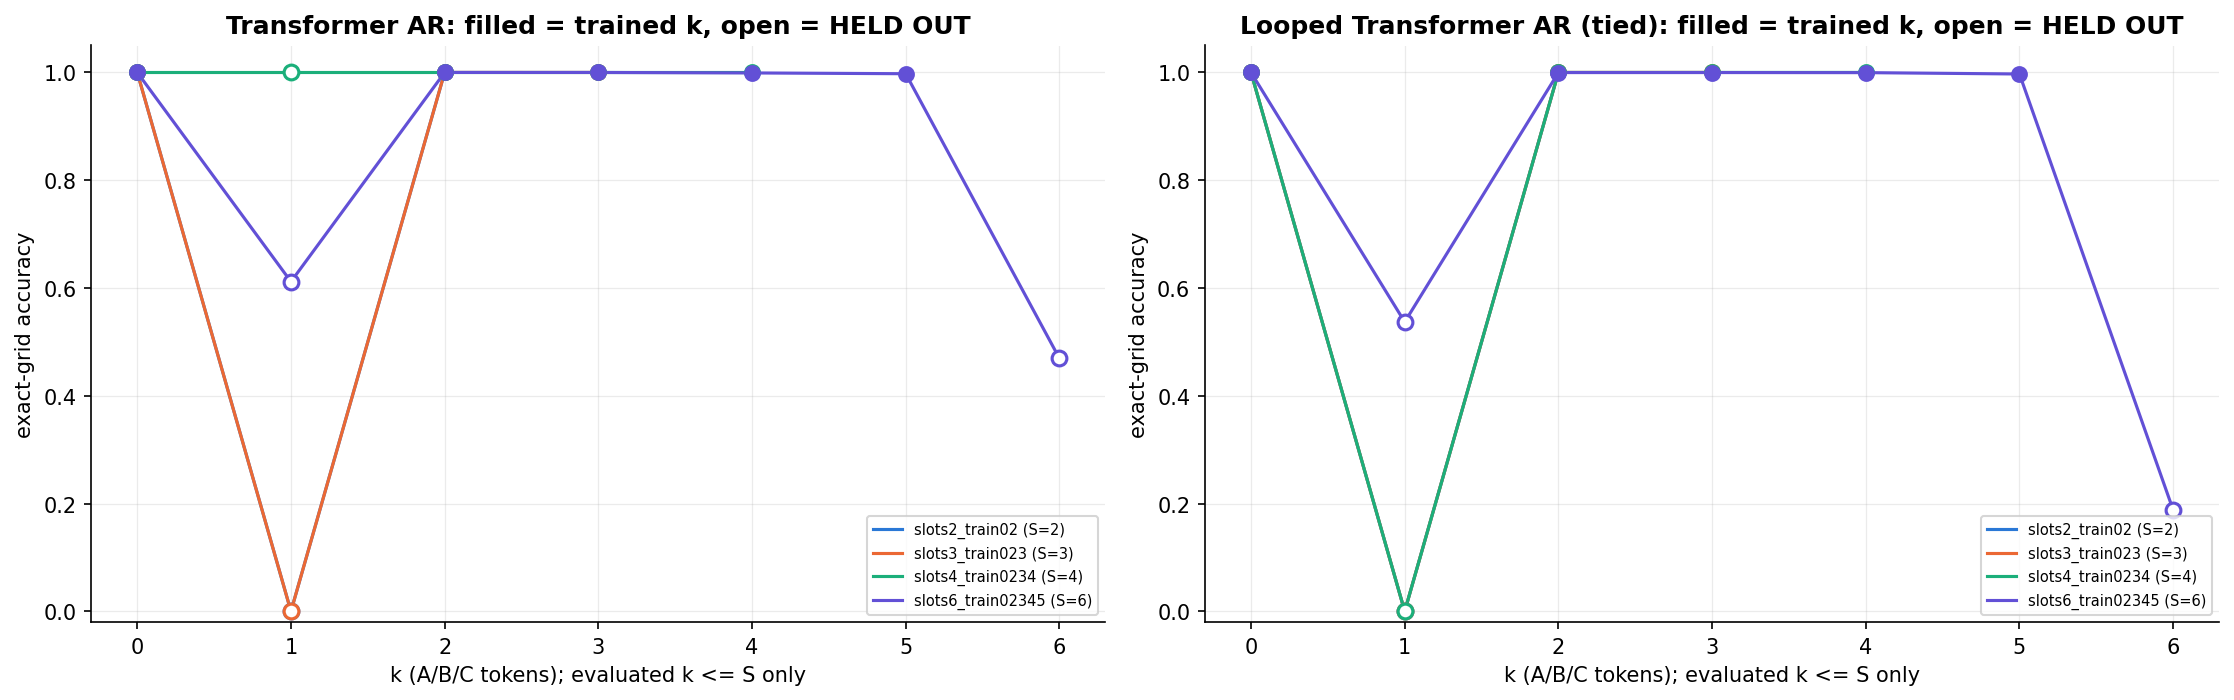

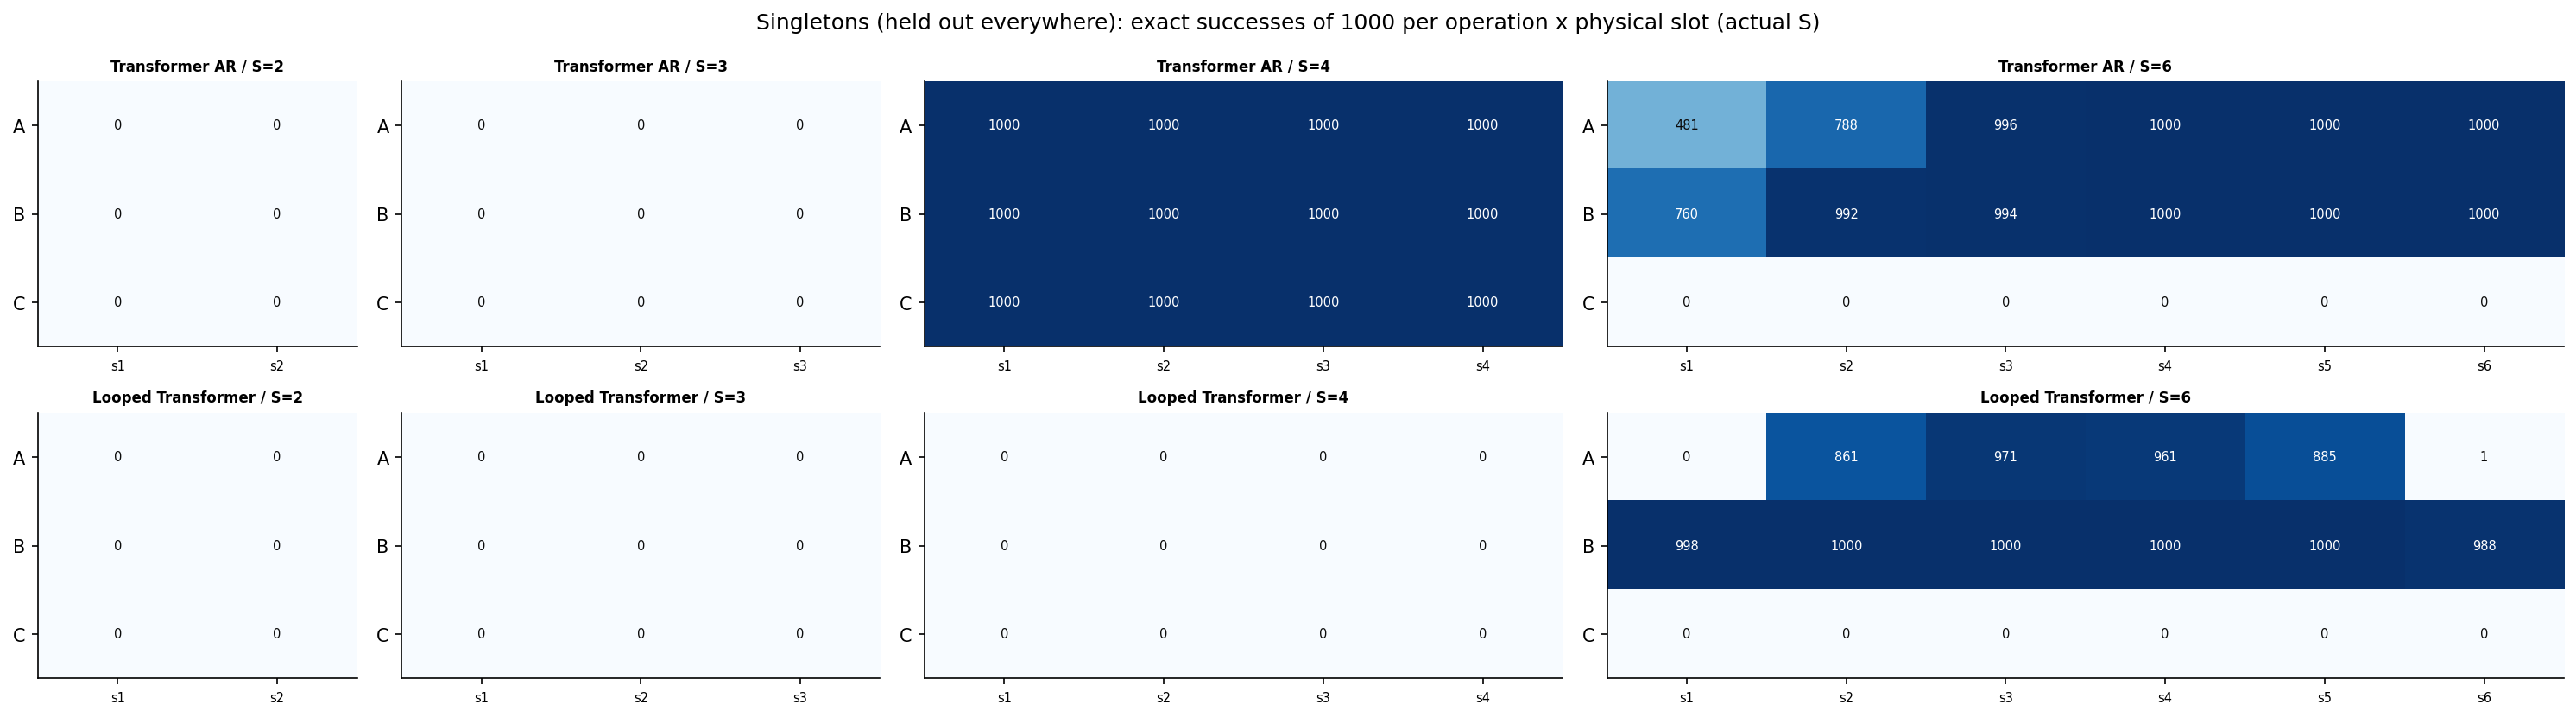

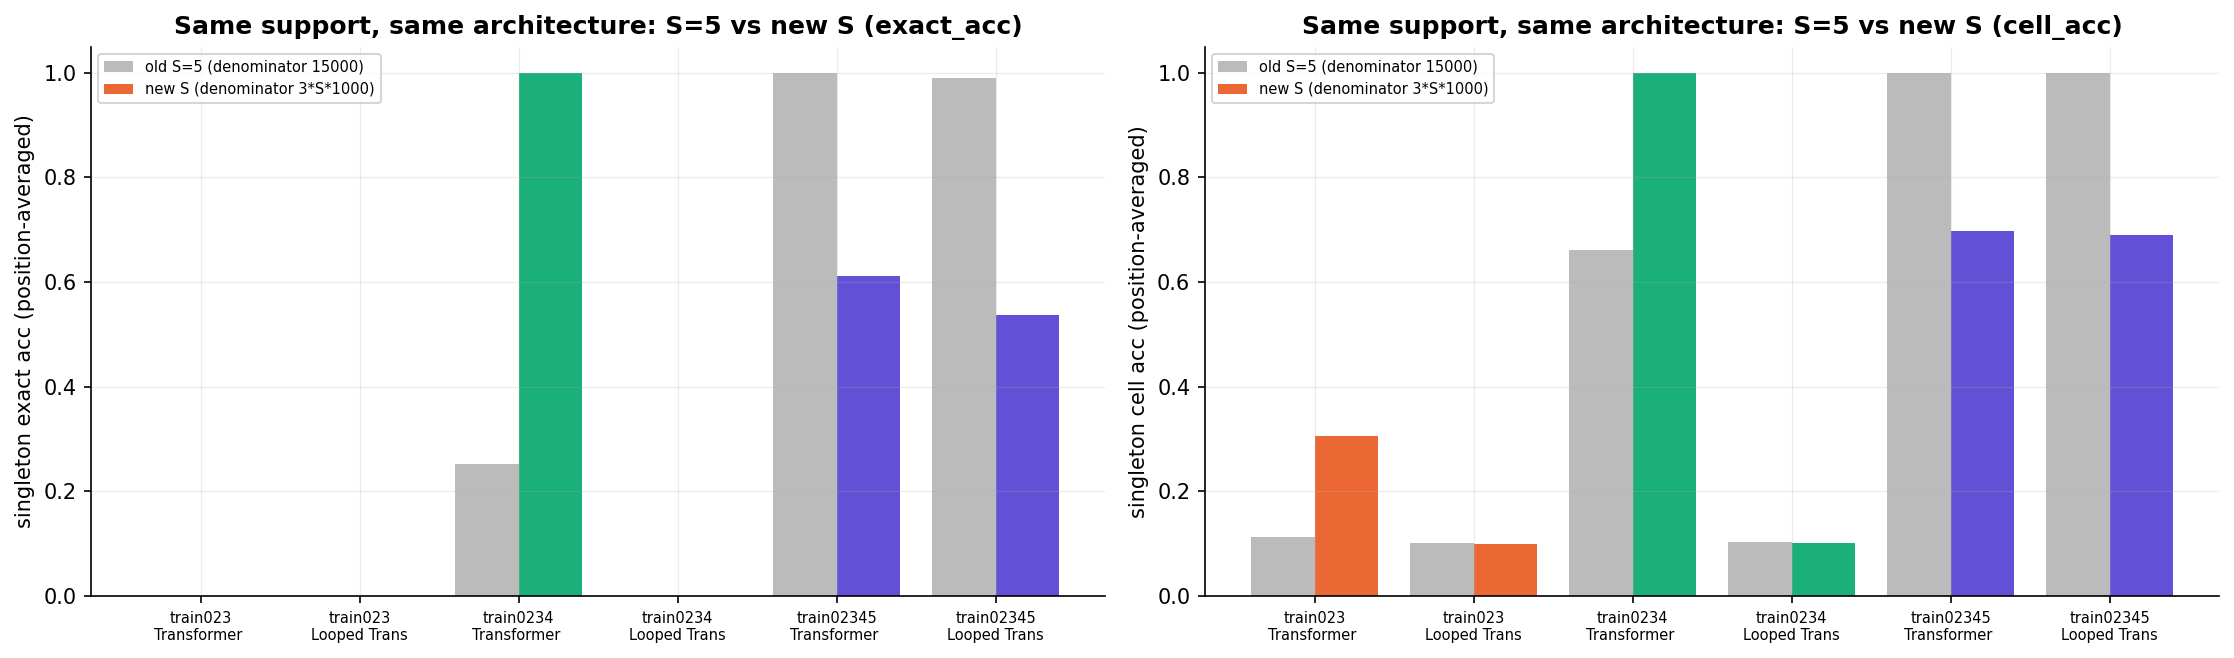

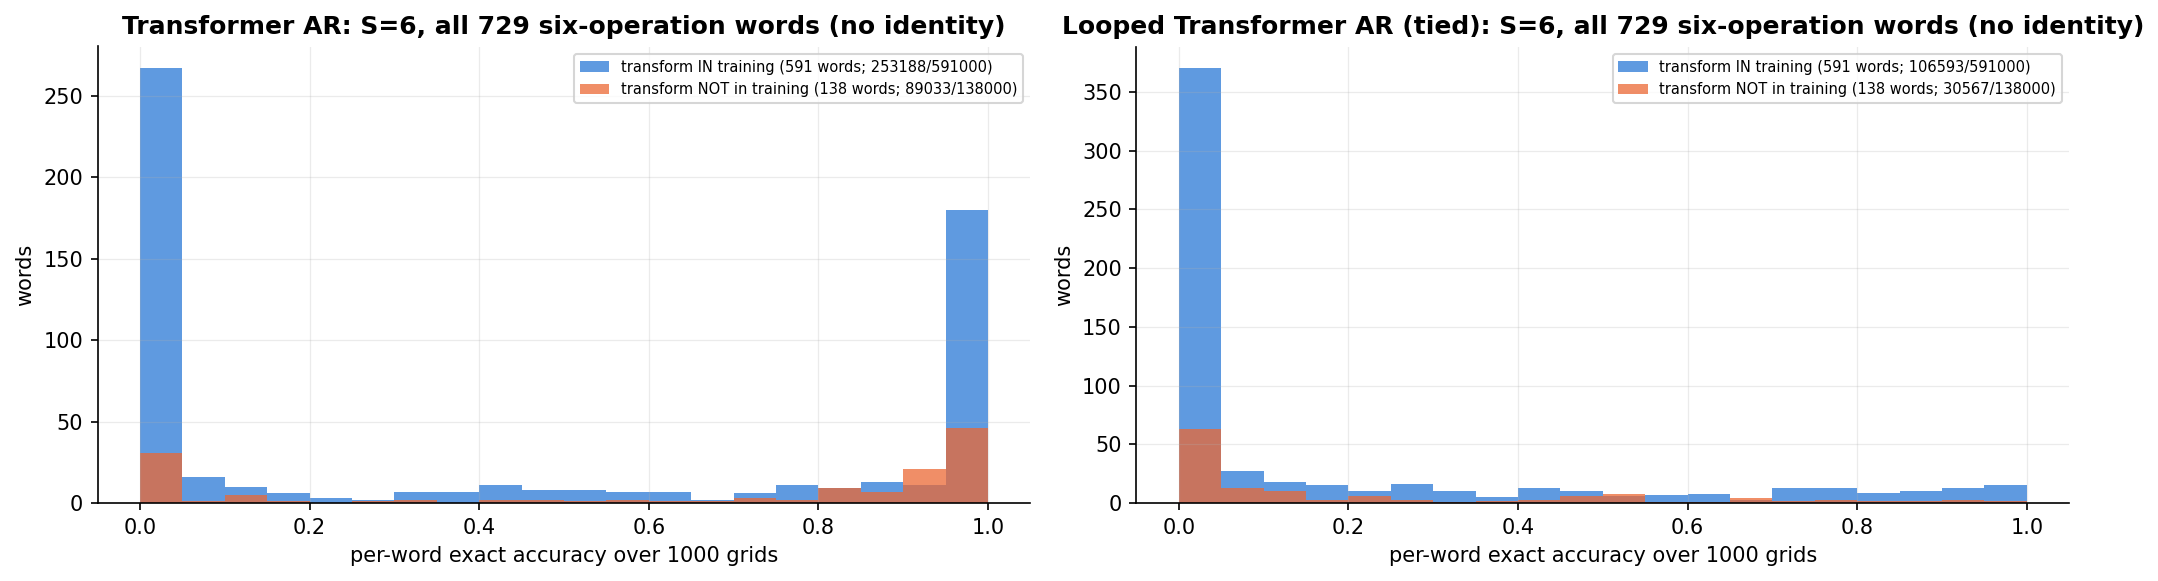

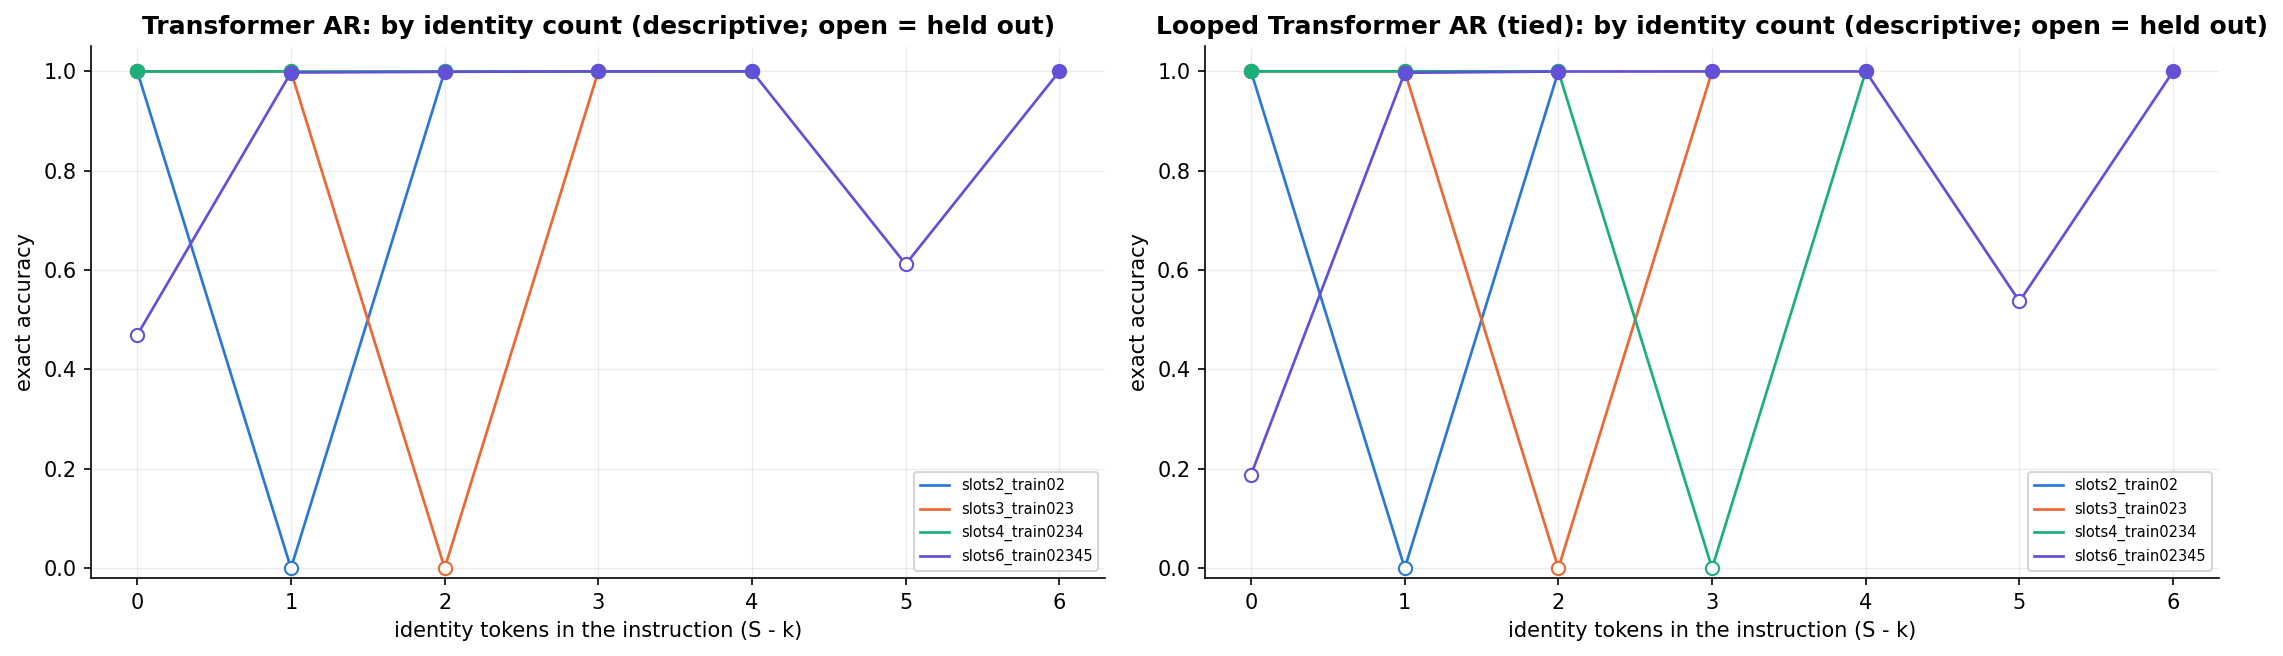

(a) main table


,condition,S,model,train_k,no_identity_training_fraction,status,seen_exact,seen_cell,singleton_exact,singleton_cell,singleton_denominator,six_op_exact,six_op_exact_transform_IN_training,six_op_exact_transform_NOT_in_training
0,slots2_train02,2,transformer_ar,"[0, 2]",0.5000,analysed,10000/10000 (1.0000),1.0000,0/6000 (0.0000 macro over 6 cells),0.0995,3*2*1000 = 6000,N/A,NaN,NaN
1,slots2_train02,2,looped_transformer_ar,"[0, 2]",0.5000,analysed,10000/10000 (1.0000),1.0000,0/6000 (0.0000 macro over 6 cells),0.0992,3*2*1000 = 6000,N/A,NaN,NaN
2,slots3_train023,3,transformer_ar,"[0, 2, 3]",0.3333,analysed,36999/37000 (1.0000),1.0000,0/9000 (0.0000 macro over 9 cells),0.3052,3*3*1000 = 9000,N/A,NaN,NaN
3,slots3_train023,3,looped_transformer_ar,"[0, 2, 3]",0.3333,analysed,37000/37000 (1.0000),1.0000,0/9000 (0.0000 macro over 9 cells),0.0992,3*3*1000 = 9000,N/A,NaN,NaN
4,slots4_train0234,4,transformer_ar,"[0, 2, 3, 4]",0.2500,analysed,118000/118000 (1.0000),1.0000,12000/12000 (1.0000 macro over 12 cells),1.0000,3*4*1000 = 12000,N/A,NaN,NaN
5,slots4_train0234,4,looped_transformer_ar,"[0, 2, 3, 4]",0.2500,analysed,118000/118000 (1.0000),1.0000,0/12000 (0.0000 macro over 12 cells),0.1015,3*4*1000 = 12000,N/A,NaN,NaN
6,slots6_train02345,6,transformer_ar,"[0, 2, 3, 4, 5]",0.0000,analysed,360347/361000 (0.9982),0.9999,11011/18000 (0.6117 macro over 18 cells),0.6973,3*6*1000 = 18000,342221/729000 (0.4694),253188/591000,89033/138000
7,slots6_train02345,6,looped_transformer_ar,"[0, 2, 3, 4, 5]",0.0000,analysed,360263/361000 (0.9980),0.9999,9665/18000 (0.5369 macro over 18 cells),0.6895,3*6*1000 = 18000,137160/729000 (0.1881),106593/591000,30567/138000


(c) accuracy by k


,condition,S,model,k,exact_correct,n,exact_acc,cell_acc,invalid_rate,status
0,slots2_train02,2,transformer_ar,0,1000.0,1000.0,1.000000,1.000000,0.000000,trained k (new grids)
1,slots2_train02,2,transformer_ar,1,0.0,6000.0,0.000000,0.099514,0.000000,HELD OUT
2,slots2_train02,2,transformer_ar,2,9000.0,9000.0,1.000000,1.000000,0.000000,trained k (new grids)
3,slots2_train02,2,looped_transformer_ar,0,1000.0,1000.0,1.000000,1.000000,0.000000,trained k (new grids)
4,slots2_train02,2,looped_transformer_ar,1,0.0,6000.0,0.000000,0.099181,0.000000,HELD OUT
5,slots2_train02,2,looped_transformer_ar,2,9000.0,9000.0,1.000000,1.000000,0.000000,trained k (new grids)
6,slots3_train023,3,transformer_ar,0,1000.0,1000.0,1.000000,1.000000,0.000000,trained k (new grids)
7,slots3_train023,3,transformer_ar,1,0.0,9000.0,0.000000,0.305167,0.000000,HELD OUT
8,slots3_train023,3,transformer_ar,2,9000.0,9000.0,1.000000,1.000000,0.000000,trained k (new grids)
9,slots3_train023,3,transformer_ar,3,26999.0,27000.0,0.999963,0.999999,0.000000,trained k (new grids)


(e) historical S=5 vs new S at the same support


,condition,support,model,S_new,S_old,status,op,old_singleton_exact,old_exact_acc,old_cell_acc,new_singleton_exact,new_exact_acc,new_cell_acc,old_first_position_exact,new_first_position_exact,paired_op_grid_units,mean_within_grid_diff_new_minus_old,units_new_higher,units_old_higher,units_equal
0,slots2_train02,train02,transformer_ar,2,5,not yet available (historical S=5 run),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,slots2_train02,train02,looped_transformer_ar,2,5,not yet available (historical S=5 run),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,slots3_train023,train023,transformer_ar,3,5,compared,A,0/5000,0.000000,0.102367,0/3000,0.000000,0.156852,0/1000,0/1000,1000.0,0.000000,0.0,0.0,1000.0
3,slots3_train023,train023,transformer_ar,3,5,compared,B,0/5000,0.000000,0.136094,0/3000,0.000000,0.659537,0/1000,0/1000,1000.0,0.000000,0.0,0.0,1000.0
4,slots3_train023,train023,transformer_ar,3,5,compared,C,0/5000,0.000000,0.099111,0/3000,0.000000,0.099111,0/1000,0/1000,1000.0,0.000000,0.0,0.0,1000.0
5,slots3_train023,train023,transformer_ar,3,5,compared,all,0/15000,0.000000,0.112524,0/9000,0.000000,0.305167,0/3000,0/3000,3000.0,0.000000,0.0,0.0,3000.0
6,slots3_train023,train023,looped_transformer_ar,3,5,compared,A,0/5000,0.000000,0.102672,0/3000,0.000000,0.098769,0/1000,0/1000,1000.0,0.000000,0.0,0.0,1000.0
7,slots3_train023,train023,looped_transformer_ar,3,5,compared,B,0/5000,0.000000,0.102928,0/3000,0.000000,0.099815,0/1000,0/1000,1000.0,0.000000,0.0,0.0,1000.0
8,slots3_train023,train023,looped_transformer_ar,3,5,compared,C,0/5000,0.000000,0.099111,0/3000,0.000000,0.099111,0/1000,0/1000,1000.0,0.000000,0.0,0.0,1000.0
9,slots3_train023,train023,looped_transformer_ar,3,5,compared,all,0/15000,0.000000,0.101570,0/9000,0.000000,0.099231,0/3000,0/3000,3000.0,0.000000,0.0,0.0,3000.0


... (9 outputs left out)

,condition,model,op,S,n_grids,grids_identical_prediction_across_all_S_placements,consistency_rate,grids_correct_at_all_placements,grids_correct_at_some_placement
0,slots2_train02,transformer_ar,A,2,1000,0,0.000,0,0
1,slots2_train02,transformer_ar,B,2,1000,0,0.000,0,0
2,slots2_train02,transformer_ar,C,2,1000,1000,1.000,0,0
3,slots2_train02,looped_transformer_ar,A,2,1000,0,0.000,0,0
4,slots2_train02,looped_transformer_ar,B,2,1000,0,0.000,0,0
5,slots2_train02,looped_transformer_ar,C,2,1000,1000,1.000,0,0
6,slots3_train023,transformer_ar,A,3,1000,0,0.000,0,0
7,slots3_train023,transformer_ar,B,3,1000,0,0.000,0,0
8,slots3_train023,transformer_ar,C,3,1000,1000,1.000,0,0
9,slots3_train023,looped_transformer_ar,A,3,1000,0,0.000,0,0


(h) audits


,model,unique_params,historical_S5_params,tied,block_applications,d_model,n_heads,d_ff,dropout,pos_table_shape,historical_pos_table_shape,identical_init_across_4_conditions,full_init_sha,shared_tensors_sha,shared_tensors_equal_historical_S5_construction,pos_rows_0_81_equal_historical,added_rows,historical_named_param_sha (idext init_audit convention)
0,transformer_ar,10703252,10702868,False,6,384,6,1536,0.0,"(83, 384)","(82, 384)",True,0c0280a531fb398d,1cb8606487640073,True,True,"row 82 from torch.Generator(seed*1000+83), std...",c8b91d15761a5cee
1,looped_transformer_ar,1830932,1830548,True,6,384,6,1536,0.0,"(83, 384)","(82, 384)",True,cebb073c9a39bd28,515575f683f4bdfd,True,True,"row 82 from torch.Generator(seed*1000+83), std...",804df113d0758967


,condition,S,model,unique_params,train_minutes,examples_per_second,peak_gpu_gb_train_session,microbatch,accumulation,oom_retries,eval_minutes,peak_gpu_gb_eval,hardware,best_step,best_val_digit_ce
0,slots2_train02,2,transformer_ar,10703252,2.497790,8540.883179,1.953628,256,1,0,0.106217,0.565296,NVIDIA RTX PRO 6000 Blackwell Server Edition,5000,2.980232e-10
1,slots2_train02,2,looped_transformer_ar,1830932,2.183407,9770.662377,1.902993,256,1,0,0.105772,0.532244,NVIDIA RTX PRO 6000 Blackwell Server Edition,5000,4.304780e-10
2,slots3_train023,3,transformer_ar,10703252,2.916942,7313.596037,1.953628,256,1,0,0.300261,0.569289,NVIDIA RTX PRO 6000 Blackwell Server Edition,4500,1.590558e-08
3,slots3_train023,3,looped_transformer_ar,1830932,2.447721,8715.591047,1.902993,256,1,0,0.299429,0.536237,NVIDIA RTX PRO 6000 Blackwell Server Edition,5000,2.465130e-10
4,slots4_train0234,4,transformer_ar,10703252,3.075683,6936.128019,1.953628,256,1,0,0.851905,0.575235,NVIDIA RTX PRO 6000 Blackwell Server Edition,5000,5.386493e-09
5,slots4_train0234,4,looped_transformer_ar,1830932,2.685721,7943.243411,1.902993,256,1,0,0.851945,0.542183,NVIDIA RTX PRO 6000 Blackwell Server Edition,4750,3.997197e-08
6,slots6_train02345,6,transformer_ar,10703252,3.568685,5977.925843,1.953628,256,1,0,7.497639,0.589081,NVIDIA RTX PRO 6000 Blackwell Server Edition,4500,6.369248e-05
7,slots6_train02345,6,looped_transformer_ar,1830932,3.106779,6866.703534,1.902993,256,1,0,7.516307,0.556029,NVIDIA RTX PRO 6000 Blackwell Server Edition,4750,6.466039e-05


In [6]:
# --- Consolidated comparison (reads saved artifacts only; rerun alone at any time) -----------------------------
res = R.analyse(FAMILY_ROOT, RESULTS_ROOT, SEED)
FIG = res["out"] / "figures"
for p in R.figures(res, FIG):
    if str(p).endswith(".png"):
        display(Image(filename=str(p)))
print("(a) main table"); display(res["main"])
print("(c) accuracy by k"); display(res["by_k"])
print("(e) historical S=5 vs new S at the same support"); display(res["historical"]); display(res["historical_meta"])
display(res["historical_paired_seen"])
print("(f) six-operation per-word (S=6)"); display(res["six_op_per_word"].sort_values(["model", "exact_acc"]) if len(res["six_op_per_word"]) else "not yet available")
print("six-operation failure subsequence checks"); display(res["six_op_subsequence"])
print("(g) identity-count view"); display(res["identity_count_view"])
print("singleton consistency across placements"); display(res["singleton_consistency"])
print("(h) audits"); display(res["audit_initialization"]); display(res["timing"])


In [7]:
# --- Export + eight-row stage status (a run is complete only when every stage is verified on disk) -------------
arch = R.export_comparisons(res)
st = R.status_table(FAMILY_ROOT, SEED); display(st)
sel = st[st.condition.isin(RUN_CONDITIONS) & st.model.isin(RUN_MODELS)]
print(f"{int(sel.complete.sum())}/{len(sel)} selected runs complete" +
      ("" if sel.complete.all() else " -> rerun Run all to resume the rest"))


comparison archive: /content/drive/MyDrive/decompositionality_results/identity_ar_slot_count/comparisons/seed_42/comparisons.zip (1.1 MiB)


,condition,S,model,train,evaluate,diagnose,export,complete,selected_step,records
0,slots2_train02,2,transformer_ar,done,done,done,done,True,5000,16000
1,slots2_train02,2,looped_transformer_ar,done,done,done,done,True,5000,16000
2,slots3_train023,3,transformer_ar,done,done,done,done,True,4500,46000
3,slots3_train023,3,looped_transformer_ar,done,done,done,done,True,5000,46000
4,slots4_train0234,4,transformer_ar,done,done,done,done,True,5000,130000
5,slots4_train0234,4,looped_transformer_ar,done,done,done,done,True,4750,130000
6,slots6_train02345,6,transformer_ar,done,done,done,done,True,4500,1108000
7,slots6_train02345,6,looped_transformer_ar,done,done,done,done,True,4750,1108000


8/8 selected runs complete


In [8]:
from google.colab import runtime

runtime.unassign()